In [ ]:
import pandas as pd

df = pd.read_csv("heart_failure_clinical_records_dataset.csv")

df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [ ]:
print("Dataset shape:", df.shape)

df.info()

df.describe().T

Dataset shape: (299, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 3

,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0


In [ ]:
missing = df.isnull().sum()

print("Missing values per column:")
print(missing)

print("Total missing values:", missing.sum())
print("Missing percentage:", df.isnull().sum().sum() / df.size * 100)

Missing values per column:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64
Total missing values: 0
Missing percentage: 0.0


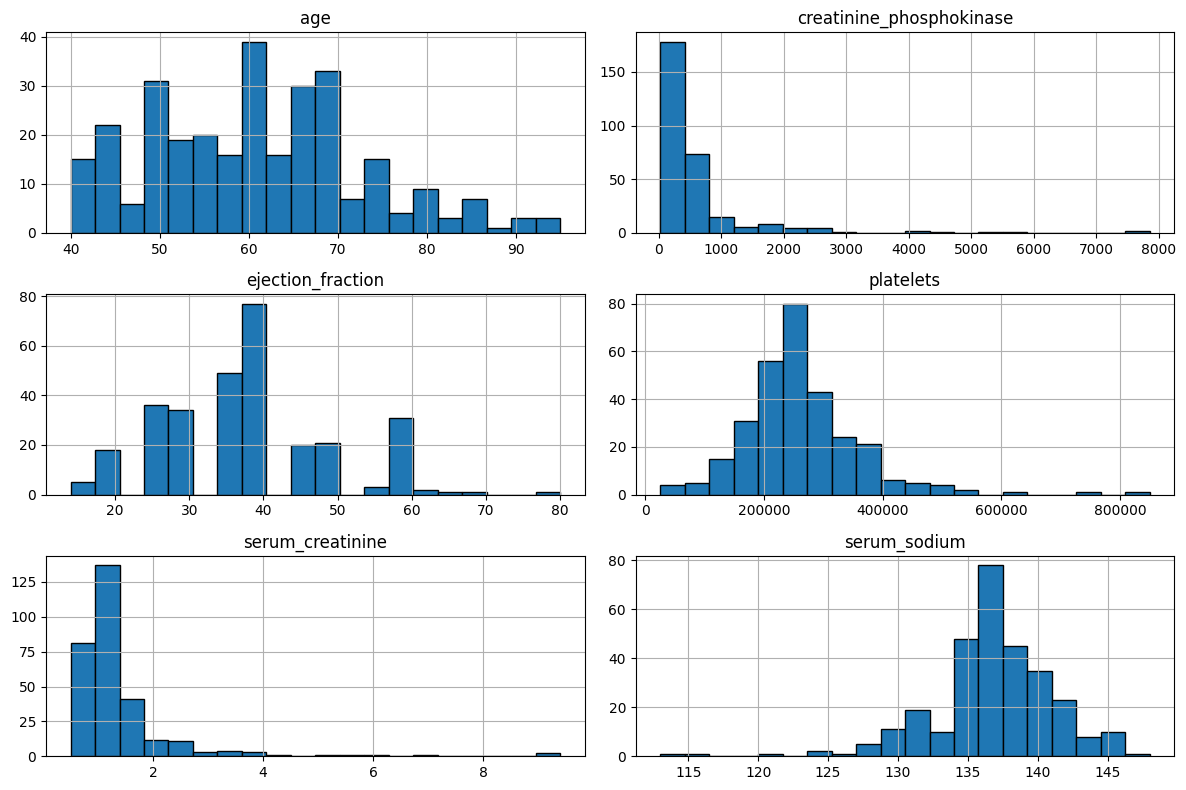

In [ ]:
import matplotlib.pyplot as plt

continuous_features = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium"
]

df[continuous_features].hist(
    figsize = (12, 8),
    bins = 20,
    edgecolor = "black"
)

plt.tight_layout()
plt.show()

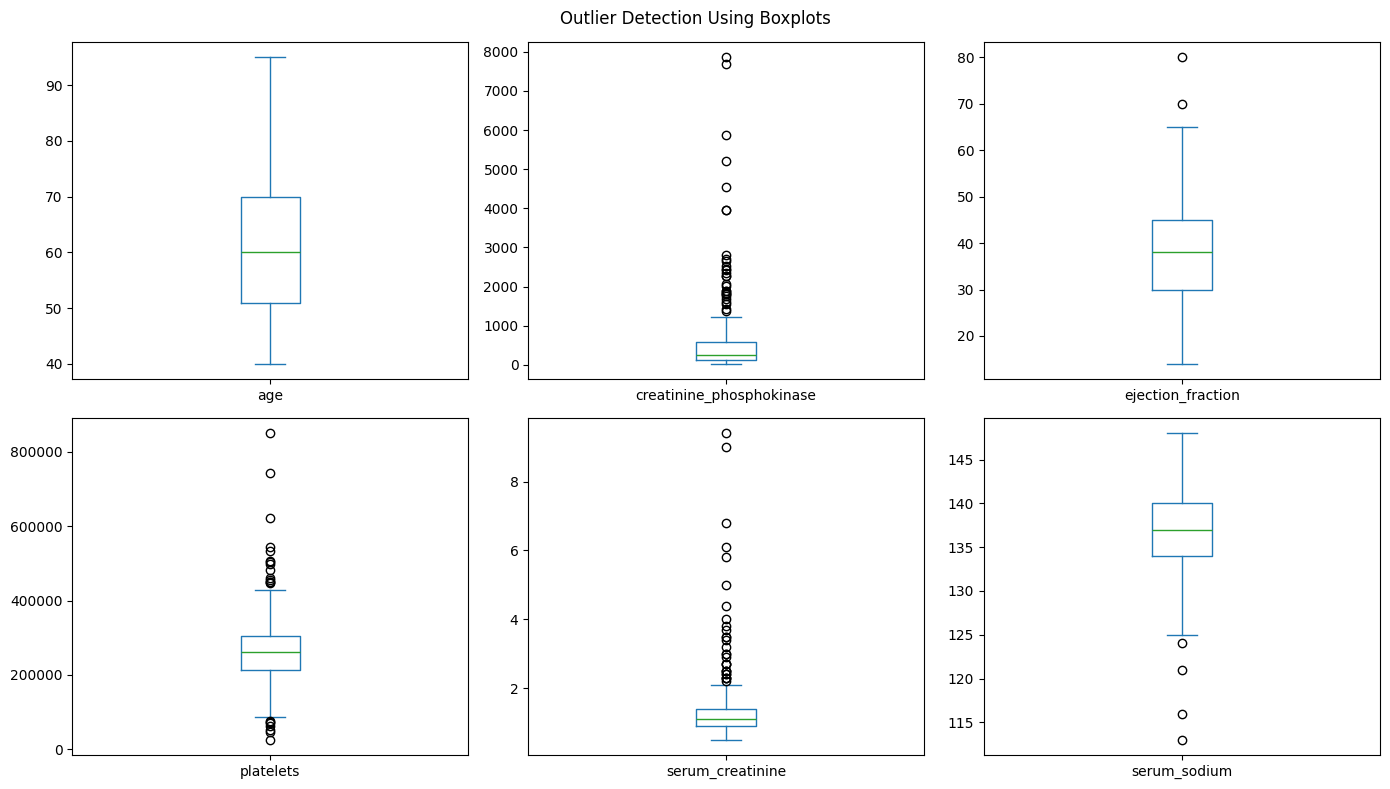

In [ ]:
import matplotlib.pyplot as plt

continuous_features = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium"
]

df[continuous_features].plot(
    kind = "box",
    subplots = True,
    layout = (2, 3),
    figsize = (14, 8),
    sharey = False
)

plt.suptitle("Outlier Detection Using Boxplots")
plt.tight_layout()
plt.show()

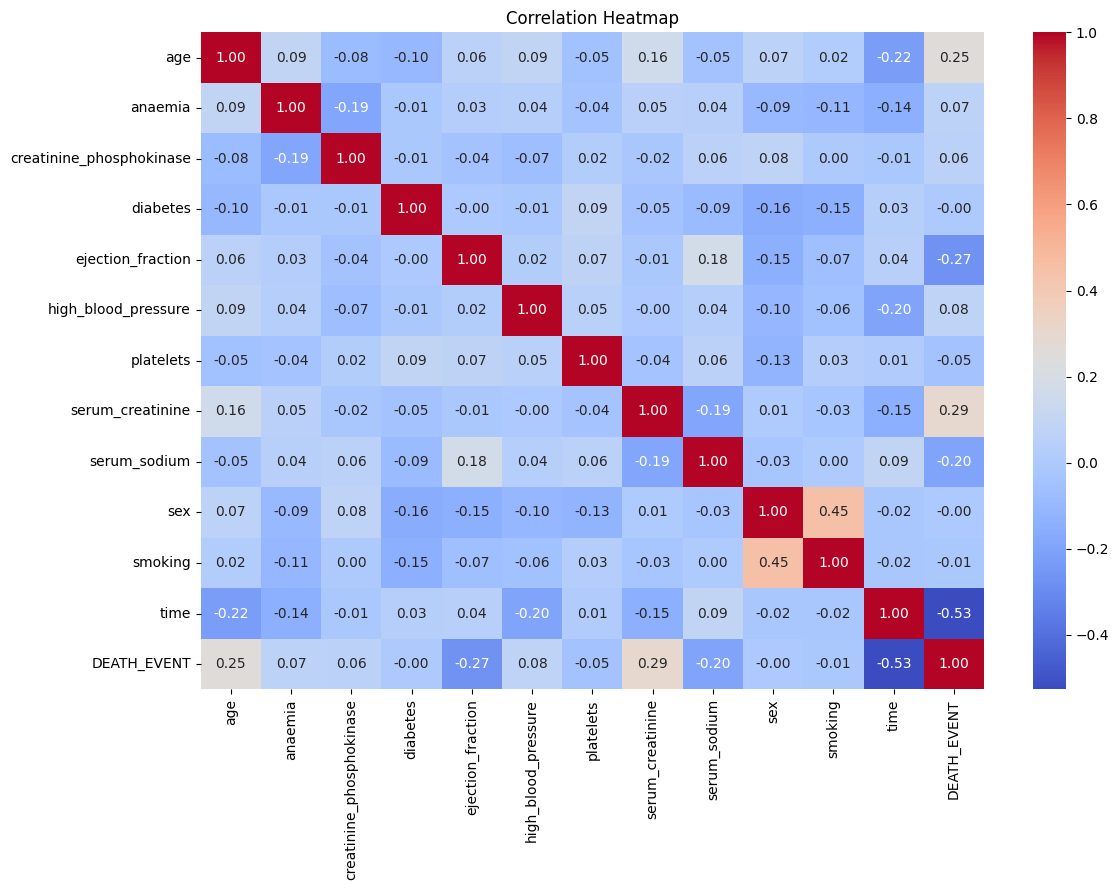

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize = (12, 9))

sns.heatmap(
    df.corr(numeric_only = True),
    annot = True,
    cmap = "coolwarm",
    fmt = ".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
%pip install lifelines

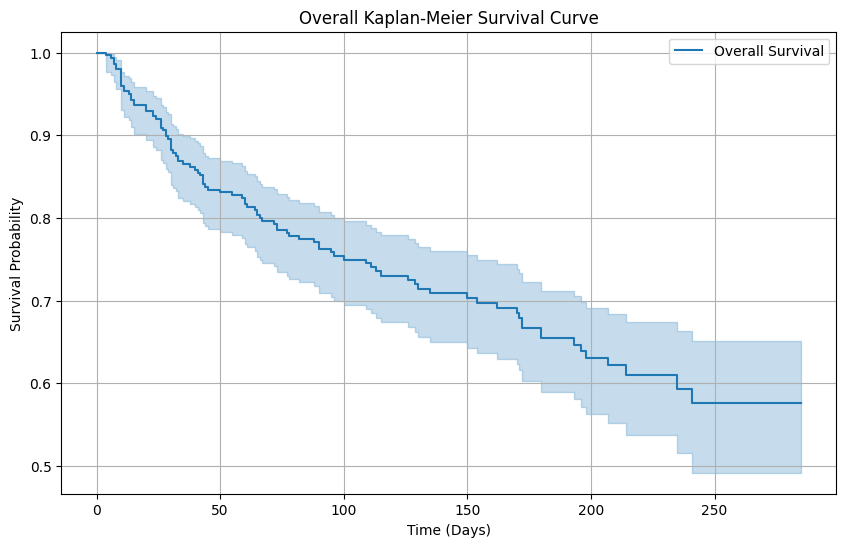

In [ ]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()

kmf.fit(
    durations = df["time"],
    event_observed = df["DEATH_EVENT"],
    label = "Overall Survival"
)

plt.figure(figsize = (10, 6))

kmf.plot_survival_function()

plt.title("Overall Kaplan-Meier Survival Curve")
plt.xlabel("Time (Days)")
plt.ylabel("Survival Probability")
plt.grid(True)
plt.show()

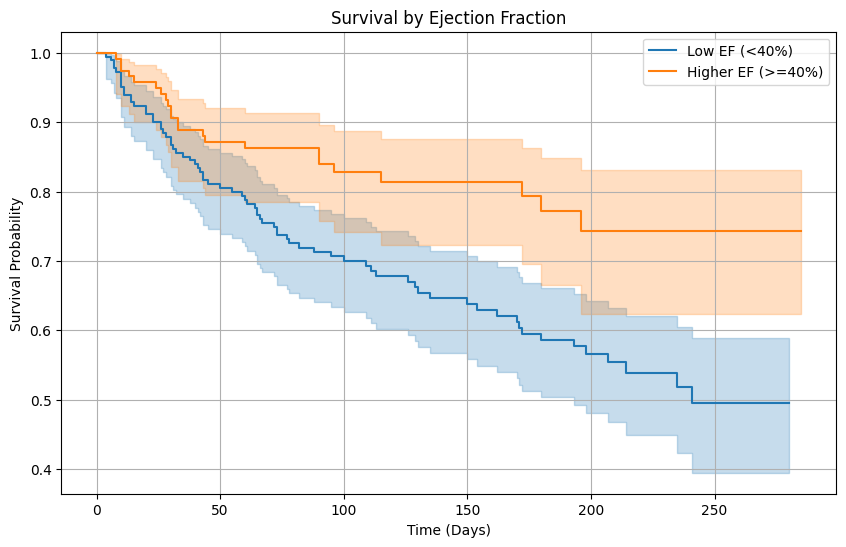

In [ ]:
low_ef = df[df["ejection_fraction"] < 40]
higher_ef = df[df["ejection_fraction"] >= 40]

kmf_low = KaplanMeierFitter()
kmf_higher = KaplanMeierFitter()

plt.figure(figsize = (10, 6))

kmf_low.fit(
    low_ef["time"],
    event_observed = low_ef["DEATH_EVENT"],
    label = "Low EF (<40%)"
)

kmf_low.plot_survival_function()

kmf_higher.fit(
    higher_ef["time"],
    event_observed = higher_ef["DEATH_EVENT"],
    label = "Higher EF (>=40%)"
)

kmf_higher.plot_survival_function()

plt.title("Survival by Ejection Fraction")
plt.xlabel("Time (Days)")
plt.ylabel("Survival Probability")
plt.grid(True)
plt.show()

In [ ]:
selected_features = [
    "age",
    "anaemia",
    "creatinine_phosphokinase",
    "diabetes",
    "ejection_fraction",
    "high_blood_pressure",
    "platelets",
    "serum_creatinine",
    "serum_sodium",
    "sex"
]

print("Number of selected features:",
      len(selected_features))

print("Selected features:")
print(selected_features)

Number of selected features: 10
Selected features:
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex']


In [ ]:
cleaned_df = df[
    selected_features + ["time", "DEATH_EVENT"]].copy()

print("Cleaned dataset shape:", cleaned_df.shape)

print("Missing values:", cleaned_df.isnull().sum().sum())

cleaned_df.head()

Cleaned dataset shape: (299, 12)
Missing values: 0


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,8,1


In [ ]:
cleaned_df.to_csv(
    "heart_failure_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold
import numpy as np

print("Cross-validation libraries imported!")

Cross-validation libraries imported!


In [ ]:
X = cleaned_df[selected_features]
y = cleaned_df["DEATH_EVENT"]

cv = RepeatedStratifiedKFold(
    n_splits = 5,
    n_repeats = 3,
    random_state = 42
)

folds = list(cv.split(X, y))

print("Total folds:", len(folds))

for i, (train_idx, test_idx) in enumerate(folds, 1):
    print(
        "Fold", i,
        "Training:", len(train_idx),
        "Testing:", len(test_idx)
    )

Total folds: 15
Fold 1 Training: 239 Testing: 60
Fold 2 Training: 239 Testing: 60
Fold 3 Training: 239 Testing: 60
Fold 4 Training: 239 Testing: 60
Fold 5 Training: 240 Testing: 59
Fold 6 Training: 239 Testing: 60
Fold 7 Training: 239 Testing: 60
Fold 8 Training: 239 Testing: 60
Fold 9 Training: 239 Testing: 60
Fold 10 Training: 240 Testing: 59
Fold 11 Training: 239 Testing: 60
Fold 12 Training: 239 Testing: 60
Fold 13 Training: 239 Testing: 60
Fold 14 Training: 239 Testing: 60
Fold 15 Training: 240 Testing: 59


In [ ]:
import json

fold_data = []

for i, (train_idx, test_idx) in enumerate(folds, 1):
    fold_data.append({
        "repeat": (i - 1) // 5 + 1,
        "fold": (i - 1) % 5 + 1,
        "train_indices": train_idx.tolist(),
        "test_indices": test_idx.tolist()
    })

with open("csv_folds.json", "w") as f:
    json.dump(fold_data, f, indent=2)

print("Cross-validation folds saved successfully!")

Cross-validation folds saved successfully!


In [ ]:
import pandas as pd
import json

# Load cleaned dataset
df_clean = pd.read_csv("heart_failure_cleaned.csv")

# Load cross-validation folds
with open("csv_folds.json", "r") as f:
    folds_check = json.load(f)

# Check cleaned dataset
print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())

assert df_clean.shape == (299, 12)
assert df_clean.isnull().sum().sum() == 0

# Check all cross-validation folds
print("Total folds:", len(folds_check))
assert len(folds_check) == 15

for i, fold in enumerate(folds_check, 1):
    train = fold["train_indices"]
    test = fold["test_indices"]

    assert len(train) == len(set(train))
    assert len(test) == len(set(test))
    assert set(train).isdisjoint(set(test))
    assert set(train) | set(test) == set(range(299))

    print(f"Fold {i}: {len(train)} train, {len(test)} test")

print("All checks passed successfully!")

Dataset shape: (299, 12)
Missing values: 0
Total folds: 15
Fold 1: 239 train, 60 test
Fold 2: 239 train, 60 test
Fold 3: 239 train, 60 test
Fold 4: 239 train, 60 test
Fold 5: 240 train, 59 test
Fold 6: 239 train, 60 test
Fold 7: 239 train, 60 test
Fold 8: 239 train, 60 test
Fold 9: 239 train, 60 test
Fold 10: 240 train, 59 test
Fold 11: 239 train, 60 test
Fold 12: 239 train, 60 test
Fold 13: 239 train, 60 test
Fold 14: 239 train, 60 test
Fold 15: 240 train, 59 test
All checks passed successfully!


# Install & Prepare Data

In [ ]:
!pip install -q lifelines

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report
from lifelines import CoxPHFitter
from lifelines.utils import concordance_index
import matplotlib.pyplot as plt

In [ ]:
# Split data into 80% Train and 20% Test (keeping the same survival/death ratio)
train_df, test_df = train_test_split(
    df, test_size=0.20, stratify=df["DEATH_EVENT"], random_state=42
)

In [ ]:
# Input features (we exclude 'time' here so the baseline model doesn't cheat)
features = [col for col in df.columns if col not in ["DEATH_EVENT", "time"]]

X_train = train_df[features]
y_train = train_df["DEATH_EVENT"]
X_test = test_df[features]
y_test = test_df["DEATH_EVENT"]

print("Training patients:", len(train_df), "| Testing patients:", len(test_df))

Training patients: 239 | Testing patients: 60


## 5. Baseline Model

Before building our main model, we test two simple starter models to set a starting score (benchmark) to beat:

1. **Dummy Model:** Always guesses that every patient survives (0). Because 68% of patients in the data survived, it gets 68% accuracy without learning anything, showing why accuracy alone isn't enough.
2. **Baseline Logistic Regression:** A basic prediction model using only initial health stats (leaving out `time` so it doesn't cheat). This gives us a fair starting score to compare against our main model.

In [ ]:
# 1. Dummy Baseline (always guesses "Survived")
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_preds = dummy.predict(X_test)
dummy_probs = dummy.predict_proba(X_test)[:, 1]

In [ ]:
# 2. Logistic Regression Baseline (scales features first)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

baseline_lr = LogisticRegression(class_weight="balanced", random_state=42)
baseline_lr.fit(X_train_scaled, y_train)
lr_preds = baseline_lr.predict(X_test_scaled)
lr_probs = baseline_lr.predict_proba(X_test_scaled)[:, 1]

In [ ]:
# Print Baseline Scores
print("Baseline Model Results")
print(f"Dummy Model Accuracy: {accuracy_score(y_test, dummy_preds):.2f} | ROC-AUC: {roc_auc_score(y_test, dummy_probs):.2f}")
print(f"Logistic Regression Accuracy: {accuracy_score(y_test, lr_preds):.2f} | ROC-AUC: {roc_auc_score(y_test, lr_probs):.2f}")
print("\nDetailed Report (Baseline Logistic Regression):")
print(classification_report(y_test, lr_preds, target_names=["Survived", "Death"]))

Baseline Model Results
Dummy Model Accuracy: 0.68 | ROC-AUC: 0.50
Logistic Regression Accuracy: 0.70 | ROC-AUC: 0.73

Detailed Report (Baseline Logistic Regression):
              precision    recall  f1-score   support

    Survived       0.78      0.78      0.78        41
       Death       0.53      0.53      0.53        19

    accuracy                           0.70        60
   macro avg       0.65      0.65      0.65        60
weighted avg       0.70      0.70      0.70        60



## Model Selection and Training: Cox Proportional Hazards Model

### Why We Selected This Model
Basic models only guess if a patient will survive (Yes or No) and ignore the time column (how many days the patient was tracked). We chose the **Cox Proportional Hazards model** because it is a special medical model built to predict patient risk over time.

### Key Advantages
* **Uses Follow-Up Days Safely:** Unlike basic models, it can safely use the time column without cheating.
* **Handles Patients Still Alive at the End:** Many patients were still alive when the study ended (DEATH_EVENT = 0). The Cox model properly understands that they simply survived up to that day, rather than assuming they are cured forever.
* **Easy for Doctors to Understand:** It shows exactly which health stats (like older age or poor kidney test results) raise a patient's risk the most.

### Why It Fits This Problem
In a real hospital, doctors need to know which patients are in danger sooner so they can treat them first. Because the Cox model ranks patients from lowest to highest risk over time, it is the best fit for heart failure care.

In [ ]:
# Train the Cox Proportional Hazards Model using 'time' and 'DEATH_EVENT'
cph = CoxPHFitter(penalizer=0.01)
cph.fit(train_df, duration_col="time", event_col="DEATH_EVENT")

<lifelines.CoxPHFitter: fitted with 239 total observations, 162 right-censored observations>

In [ ]:
# Show the statistical summary (Hazard Ratios & p-values)
cph.print_summary(decimals=3)

<lifelines.CoxPHFitter: fitted with 239 total observations, 162 right-censored observations>
             duration col = 'time'
                event col = 'DEATH_EVENT'
                penalizer = 0.01
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 239
number of events observed = 77
   partial log-likelihood = -360.593
         time fit was run = 2026-11-24 16:00:15 UTC

---
                           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                  
age                       0.038     1.039     0.011           0.017           0.059               1.017               1.061
anaemia                   0.480     1.616     0.239           0.011           0.949               1.011               2.583
creatinine_phosphokinase  0.000     1.000     0.000           0.000           0.000               1.000               1.000
diabetes                  0.386     1.471     0.249          -0.103           0.875               0.902               2.398
ejection_fraction        -0.050     0.952     0.011          -0.072          -0.027               0.931               0.973
high_blood_pressure       0.502     1.651     0.235           0.040           0.963               1.041               2.619
platelets                -0.000     1.000     0.000          -0.000           0.000               1.000               1.000
serum_creatinine          0.335     1.397     0.072           0.193           0.476               1.213               1.610
serum_sodium             -0.030     0.970     0.025          -0.080           0.019               0.923               1.019
sex                      -0.172     0.842     0.277          -0.716           0.371               0.489               1.449
smoking                   0.301     1.351     0.273          -0.233           0.835               0.792               2.306

                          cmp to      z       p  -log2(p)
covariate                                                
age                        0.000  3.562 <0.0005    11.405
anaemia                    0.000  2.004   0.045     4.472
creatinine_phosphokinase   0.000  2.226   0.026     5.265
diabetes                   0.000  1.547   0.122     3.037
ejection_fraction          0.000 -4.355 <0.0005    16.197
high_blood_pressure        0.000  2.131   0.033     4.919
platelets                  0.000 -0.538   0.590     0.761
serum_creatinine           0.000  4.631 <0.0005    18.070
serum_sodium               0.000 -1.208   0.227     2.140
sex                        0.000 -0.622   0.534     0.905
smoking                    0.000  1.105   0.269     1.892
---
Concordance = 0.743
Partial AIC = 743.185
log-likelihood ratio test = 62.367 on 11 df
-log2(p) of ll-ratio test = 28.149

In [ ]:
# Predict risk scores on the test patients
cox_risk_scores = cph.predict_partial_hazard(X_test)

In [ ]:
# Calculate C-Index (0.50 = random guess, 1.00 = perfect risk ranking) and ROC-AUC
baseline_c_index = concordance_index(test_df["time"], -lr_probs, y_test)
cox_c_index = concordance_index(test_df["time"], -cox_risk_scores, y_test)
cox_auc = roc_auc_score(y_test, cox_risk_scores)

In [ ]:
# Compare Baseline vs. Cox Model
comparison = pd.DataFrame({
    "Model": ["Baseline (Logistic Regression)", "Cox Proportional Hazards Model"],
    "ROC-AUC": [round(roc_auc_score(y_test, lr_probs), 3), round(cox_auc, 3)],
    "C-Index (Survival Ranking)": [round(baseline_c_index, 3), round(cox_c_index, 3)]
})

print("\n--- Final Comparison: Baseline vs. Cox Model ---")
display(comparison)


--- Final Comparison: Baseline vs. Cox Model ---


,Model,ROC-AUC,C-Index (Survival Ranking)
0,Baseline (Logistic Regression),0.734,0.690
1,Cox Proportional Hazards Model,0.763,0.724


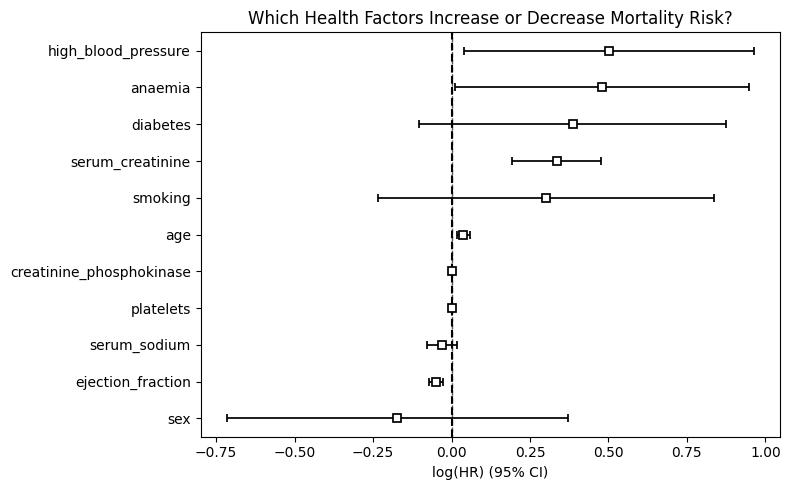

In [ ]:
# Plot which health factors increase or decrease risk
plt.figure(figsize=(8, 5))
cph.plot()
plt.title("Which Health Factors Increase or Decrease Mortality Risk?")
plt.axvline(0, color="black", linestyle="--")
plt.tight_layout()
plt.show()

### Conclusion (single 80/20 split)
On this one split, the Cox model scored higher than the logistic regression baseline (ROC-AUC 0.763 vs. 0.734, C-index 0.724 vs. 0.690). The test set has only 60 patients and 19 deaths, so these numbers are noisy and the comparison is not conclusive. The cross-validated results later in this notebook are the ones to report.

Two cautions about this section:
* It uses all 11 predictors (including smoking), while the cross-validated section uses the 10 selected features.
* The per-unit Cox coefficients cannot be compared between variables measured on different scales, so they do not show which factor is "biggest". The standardised hazard ratios and the permutation importance further down show that ejection fraction (protective), serum creatinine and age are the main drivers, while blood pressure and anaemia contribute little.

## Cox Model on Two Variables

In [ ]:
#Cox Model on 2 Variables (ejection_fraction and serum_creatinine)
cph_two = CoxPHFitter()
cph_two.fit(
    train_df[["ejection_fraction", "serum_creatinine", "time", "DEATH_EVENT"]],
    duration_col="time",
    event_col="DEATH_EVENT"
)
cph_two.print_summary(decimals=3)

<lifelines.CoxPHFitter: fitted with 239 total observations, 162 right-censored observations>
             duration col = 'time'
                event col = 'DEATH_EVENT'
      baseline estimation = breslow
   number of observations = 239
number of events observed = 77
   partial log-likelihood = -372.998
         time fit was run = 2026-11-24 16:00:32 UTC

---
                    coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                           
ejection_fraction -0.049     0.952     0.011          -0.070          -0.028               0.932               0.973
serum_creatinine   0.381     1.463     0.069           0.246           0.516               1.279               1.675

                   cmp to      z       p  -log2(p)
covariate                                         
ejection_fraction   0.000 -4.503 <0.0005    17.189
serum_creatinine    0.000  5.533 <0.0005    24.919
---
Concordance = 0.682
Partial AIC = 749.997
log-likelihood ratio test = 37.555 on 2 df
-log2(p) of ll-ratio test = 27.090

In [ ]:
#Check Proportional Hazards Assumption on the Full Cox Model
cph.check_assumptions(train_df, p_value_threshold=0.05)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'ejection_fraction' failed the non-proportional test: p-value is 0.0028.

   Advice 1: the functional form of the variable 'ejection_fraction' might be incorrect. That is,
there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'ejection_fraction' using pd.cut, and then specify it in
`strata=['ejection_fraction', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'serum_creatinine' failed the non-proportional test: p-value is 0.0176.

   Advice 1: the functional form of the variable 'serum_creatinine' might be incorrect. That is,
there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentat

[]

Model Development and Evaluation

In this part of our project, we compare different survival analysis models to see how well they predict patient risk over time. We use the 10 features selected during our exploratory data analysis and evaluate the models using 5-fold cross-validation repeated 3 times, giving us 15 train-test splits. We keep the random seed at 42 to make our results reproducible.

We do not use the time column as an input feature because it represents the patient's follow-up duration. Instead, we use time and DEATH_EVENT together to define the survival outcome.

We compare the models using the C-index, time-dependent AUC and integrated Brier score. We also examine feature importance and perform error analysis to understand which factors influence the predictions and which patient groups are more difficult to predict accurately.

We save the results, tables and graphs in the project_results folder for further analysis and comparison.

Dataset: UCI Heart Failure Clinical Records (CC BY 4.0, DOI: 10.24432/C5Z89R).


In [ ]:
%pip install -q scikit-survival

In [ ]:
%pip install -q "scikit-learn==1.9.1" "scikit-survival==0.28.0"

In [ ]:
from importlib.metadata import version, PackageNotFoundError

required_versions = {
    "scikit-learn": "1.9.1",
    "scikit-survival": "0.28.0"
}

for package, required in required_versions.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        raise RuntimeError(
            f"{package} is missing. Run the first setup cell "
            "and restart the session."
        )

    if installed != required:
        raise RuntimeError(
            f"{package} is version {installed}; expected {required}. "
            "Run the first setup cell and restart the session."
        )

print("Required ML packages are installed. Continuing with the project.")

Required ML packages are installed. Continuing with the project.


In [ ]:
from importlib.metadata import version, PackageNotFoundError
import subprocess
import sys

required_versions = {
    "scikit-learn": "1.9.1",
    "scikit-survival": "0.28.0",
}

versions_match = True
for package, expected in required_versions.items():
    try:
        versions_match = versions_match and version(package) == expected
    except PackageNotFoundError:
        versions_match = False

if not versions_match:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "scikit-learn==1.9.1", "scikit-survival==0.28.0",
    ])
    raise RuntimeError(
        "Setup installed compatible ML packages. Now choose Runtime > "
        "Restart session, then Run all. Do not continue in this session."
    )

# Test the compiled imports while there is still no model state to lose.
from sklearn.inspection import permutation_importance
from sksurv.linear_model import CoxPHSurvivalAnalysis
print("ML dependencies are compatible. Continue with the project notebook.")

ML dependencies are compatible. Continue with the project notebook.


In [ ]:
from pathlib import Path
from collections import Counter
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from lifelines import KaplanMeierFitter
from sksurv.util import Surv
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.ensemble import RandomSurvivalForest, GradientBoostingSurvivalAnalysis
from sksurv.metrics import (
    concordance_index_censored, cumulative_dynamic_auc, integrated_brier_score
)

SEED = 42
RESULTS_DIR = Path("project_results")
RESULTS_DIR.mkdir(exist_ok=True)

# Reuse the cleaned data, the ten feature names and the saved outer folds from the sections above.
X_survival = cleaned_df[selected_features].reset_index(drop=True).astype(float)
y_survival = Surv.from_arrays(
    event = cleaned_df["DEATH_EVENT"].to_numpy().astype(bool),
    time = cleaned_df["time"].to_numpy().astype(float)
)
outer_folds = [
    (np.array(f["train_indices"], dtype = int), np.array(f["test_indices"], dtype = int))
    for f in folds_check
]

assert len(selected_features) <= 10 and "time" not in selected_features
assert len(X_survival) == 299 and len(outer_folds) == 15
assert not X_survival.isna().any().any()

# Fixed evaluation horizons for fair comparisons on this 4-285-day dataset.
AUC_TIMES = np.array([60.0, 120.0, 180.0])
IBS_TIMES = np.linspace(30.0, 180.0, 16)

print("Patients:", len(X_survival))
print("Deaths:", int(y_survival["event"].sum()))
print("Features:", selected_features)
print("Outer CV folds:", len(outer_folds))
print("AUC horizons (days):", AUC_TIMES.tolist())

Patients: 299
Deaths: 96
Features: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex']
Outer CV folds: 15
AUC horizons (days): [60.0, 120.0, 180.0]


### Supporting evidence: censoring, group comparisons and feature selection

These cells give the evidence behind three choices in the report: why survival analysis is needed (censoring), whether the clinical groups differ in survival (log-rank tests), and why the final model uses ten features.

Patients: 299
Deaths: 96 (32.1%)
Censored (alive at the end of follow-up): 203 (67.9%)

Follow-up time in days:
count    299.0
mean     130.3
std       77.6
min        4.0
25%       73.0
50%      115.0
75%      203.0
max      285.0


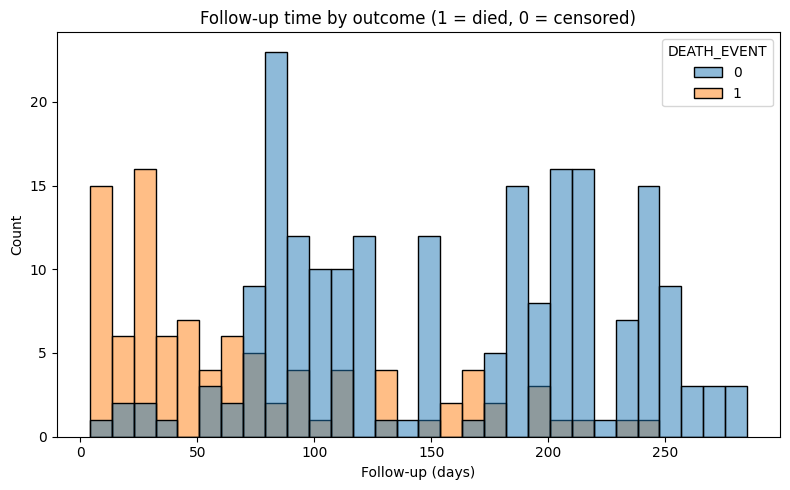

In [ ]:
# Censoring summary
n_total = len(cleaned_df)
n_dead = int(cleaned_df["DEATH_EVENT"].sum())
print(f"Patients: {n_total}")
print(f"Deaths: {n_dead} ({n_dead / n_total:.1%})")
print(f"Censored (alive at the end of follow-up): {n_total - n_dead} ({(n_total - n_dead) / n_total:.1%})")
print("\nFollow-up time in days:")
print(cleaned_df["time"].describe().round(1).to_string())

fig, ax = plt.subplots(figsize = (8, 5))
sns.histplot(data = cleaned_df, x = "time", hue = "DEATH_EVENT", bins = 30, ax = ax)
ax.set_title("Follow-up time by outcome (1 = died, 0 = censored)")
ax.set_xlabel("Follow-up (days)")
plt.tight_layout()
plt.show()

In [ ]:
# Log-rank tests: do the clinical groups have different survival?
from sksurv.compare import compare_survival

group_splits = {
    "Ejection fraction < 40%": cleaned_df["ejection_fraction"] < 40,
    "Serum creatinine > 1.5": cleaned_df["serum_creatinine"] > 1.5,
    "Age >= 65": cleaned_df["age"] >= 65,
    "Anaemia": cleaned_df["anaemia"] == 1,
}
logrank_rows = []
for split_name, in_group in group_splits.items():
    chi2, p_value = compare_survival(y_survival, in_group.astype(int).to_numpy())
    logrank_rows.append({
        "Group split": split_name,
        "Patients in group": int(in_group.sum()),
        "Deaths in group": int(y_survival["event"][in_group.to_numpy()].sum()),
        "Log-rank chi-square": chi2,
        "p-value": p_value,
    })
logrank_table = pd.DataFrame(logrank_rows)
logrank_table.to_csv(RESULTS_DIR / "logrank_tests.csv", index = False)
display(logrank_table.round(4))

,Group split,Patients in group,Deaths in group,Log-rank chi-square,p-value
0,Ejection fraction < 40%,182,73,9.4696,0.0021
1,Serum creatinine > 1.5,67,43,39.6117,0.0000
2,Age >= 65,115,50,12.8812,0.0003
3,Anaemia,129,46,2.7265,0.0987


In [ ]:
# Univariate C-index of each of the 11 candidate predictors (0.5 = no ranking ability)
y_all = Surv.from_arrays(
    event = df["DEATH_EVENT"].to_numpy().astype(bool),
    time = df["time"].to_numpy().astype(float)
)
candidate_features = [c for c in df.columns if c not in ["time", "DEATH_EVENT"]]

ranking_rows = []
for feature in candidate_features:
    c = concordance_index_censored(
        y_all["event"], y_all["time"], df[feature].to_numpy().astype(float)
    )[0]
    ranking_rows.append({
        "Feature": feature,
        "Univariate C-index": max(c, 1 - c),
        "Higher value means": "higher risk" if c >= 0.5 else "lower risk",
        "Used in final models": feature in selected_features,
    })
feature_ranking = (pd.DataFrame(ranking_rows)
                   .sort_values("Univariate C-index", ascending = False)
                   .reset_index(drop = True))
feature_ranking.to_csv(RESULTS_DIR / "univariate_feature_ranking.csv", index = False)
display(feature_ranking.round(3))

,Feature,Univariate C-index,Higher value means,Used in final models
0,serum_creatinine,0.667,higher risk,True
1,age,0.628,higher risk,True
2,ejection_fraction,0.618,lower risk,True
3,serum_sodium,0.596,lower risk,True
4,high_blood_pressure,0.556,higher risk,True
5,anaemia,0.545,higher risk,True
6,creatinine_phosphokinase,0.523,lower risk,True
7,platelets,0.510,lower risk,True
8,smoking,0.506,higher risk,False
9,sex,0.505,higher risk,True


**Feature selection.** Smoking was removed because it has almost no individual ranking ability (univariate C-index close to 0.5, see the table) and it is partly redundant with sex (correlation of about 0.45 in the heatmap). Sex, diabetes and platelets are also weak, but they were kept for clinical relevance and so that the models, not a pre-filter, decide how much they matter; the permutation importance later confirms they contribute almost nothing. The ranking was computed on the full dataset, which leaks a small amount of information into the cross-validation estimate. This should be stated as a limitation.

**Stationarity.** Stationarity analysis does not apply here: each patient has a single baseline measurement and one follow-up outcome, so the data is a cross-sectional cohort and not a time series.

### Model evaluation and nested tuning

- **Kaplan–Meier:** no individual features; a non-personalised survival-probability baseline.
- **Logistic regression:** predicts observed death status, not death *time*; included for a
  comparison illustrating why censoring must be taken into account. It cannot produce
  a valid time-dependent survival curve, so its integrated Brier score is not reported.
- **Cox (two features):** ejection fraction and serum creatinine.
- **Cox (ten features):** all selected predictors.
- **Random Survival Forest and Gradient Boosting:** hyperparameters selected by 3-fold
  **inner** CV for each outer training split. Outer test data is not used for tuning.

The C-index measures risk ordering (higher is better). Time-dependent AUC is computed
at 60, 120, and 180 days (higher is better). Integrated Brier score assesses the
survival probabilities between 30 and 180 days (lower is better). Censoring-aware
metrics use the training fold for inverse probability of censoring weights (IPCW).

For folds where a test patient's follow-up extends beyond the maximum training
follow-up, that patient is excluded **only** from IPCW-based AUC/Brier calculations
because the training censoring distribution cannot be estimated beyond its support;
all patients remain in the C-index. The excluded count is recorded.

Method reference: [scikit-survival evaluation guide](https://scikit-survival.readthedocs.io/en/stable/user_guide/evaluating-survival-models.html).

In [ ]:
def model_survival_probabilities(model, X, times):
    # Survival S(t) for every patient at every requested time.
    functions = model.predict_survival_function(X)
    return np.asarray([[float(fn(t)) for t in times] for fn in functions])


def evaluate_survival_predictions(name, fold_number, y_train, y_test,
                                  risk_scores, survival_probs = None):
    risk_scores = np.asarray(risk_scores).reshape(-1)
    c_index = concordance_index_censored(
        y_test["event"], y_test["time"], risk_scores
    )[0]

    # IPCW estimators require the held-out follow-up to lie within train support.
    eligible = y_test["time"] < y_train["time"].max()
    y_test_ipcw = y_test[eligible]
    auc_values, mean_auc = cumulative_dynamic_auc(
        y_train, y_test_ipcw, risk_scores[eligible], AUC_TIMES
    )
    ibs = np.nan
    if survival_probs is not None:
        ibs = integrated_brier_score(
            y_train, y_test_ipcw, survival_probs[eligible], IBS_TIMES
        )

    return {
        "Fold": fold_number,
        "Model": name,
        "C-index": float(c_index),
        "AUC 60d": float(auc_values[0]),
        "AUC 120d": float(auc_values[1]),
        "AUC 180d": float(auc_values[2]),
        "Mean time-dependent AUC": float(mean_auc),
        "Integrated Brier score": float(ibs),
        "Test patients": len(y_test),
        "IPCW eligible": int(eligible.sum()),
        "IPCW excluded": int((~eligible).sum()),
    }


def inner_folds_for(y_train):
    # Build inner folds using only the training patients for this outer fold.
    cv_inner = StratifiedKFold(n_splits = 3, shuffle = True, random_state = SEED)
    return list(cv_inner.split(np.zeros(len(y_train)), y_train["event"]))


def rsf_search(inner_cv):
    return GridSearchCV(
        RandomSurvivalForest(
            n_estimators = 80, min_samples_split = 10, random_state = SEED, n_jobs = 2
        ),
        {"min_samples_leaf": [3, 8], "max_features": ["sqrt", 0.8]},
        cv = inner_cv, n_jobs = 1, error_score = "raise"
    )


def gb_search(inner_cv):
    return GridSearchCV(
        GradientBoostingSurvivalAnalysis(
            loss = "coxph", n_estimators = 100, random_state = SEED
        ),
        {"learning_rate": [0.03, 0.10], "max_depth": [1, 2]},
        cv = inner_cv, n_jobs = 1, error_score = "raise"
    )

In [ ]:
fold_results = []
best_settings = []
importance_rows = []
patient_predictions = []

for fold_number, (train_index, test_index) in enumerate(outer_folds, start=1):
    X_train_cv = X_survival.iloc[train_index]
    X_test_cv = X_survival.iloc[test_index]
    y_train_cv = y_survival[train_index]
    y_test_cv = y_survival[test_index]
    inner_cv = inner_folds_for(y_train_cv)

    # The same outer test patients are used for ALL models in this iteration.
    km_cv = KaplanMeierFitter().fit(
        y_train_cv["time"], event_observed = y_train_cv["event"]
    )
    km_prob = np.tile(
        np.asarray(km_cv.predict(IBS_TIMES)), (len(test_index), 1)
    )

    lr_cv = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter = 1000, class_weight = "balanced", random_state = SEED)
    ).fit(X_train_cv, y_train_cv["event"].astype(int))

    two_features = ["ejection_fraction", "serum_creatinine"]
    cox_two_cv = make_pipeline(
        StandardScaler(), CoxPHSurvivalAnalysis(alpha = 0.1)
    ).fit(X_train_cv[two_features], y_train_cv)

    cox_full_cv = make_pipeline(
        StandardScaler(), CoxPHSurvivalAnalysis(alpha = 0.1)
    ).fit(X_train_cv, y_train_cv)

    rsf_cv = rsf_search(inner_cv)
    rsf_cv.fit(X_train_cv, y_train_cv)
    gb_cv = gb_search(inner_cv)
    gb_cv.fit(X_train_cv, y_train_cv)

    best_settings.extend([
        {"Fold": fold_number, "Model": "Random Survival Forest",
         "Best parameters": str(rsf_cv.best_params_),
         "Inner CV C-index": rsf_cv.best_score_},
        {"Fold": fold_number, "Model": "Gradient Boosted Survival",
         "Best parameters": str(gb_cv.best_params_),
         "Inner CV C-index": gb_cv.best_score_},
    ])

    fitted_models = {
        "Cox (2 features)": (cox_two_cv, X_test_cv[two_features]),
        "Cox (10 features)": (cox_full_cv, X_test_cv),
        "Random Survival Forest": (rsf_cv.best_estimator_, X_test_cv),
        "Gradient Boosted Survival": (gb_cv.best_estimator_, X_test_cv),
    }

    fold_results.append(evaluate_survival_predictions(
        "Kaplan-Meier", fold_number, y_train_cv, y_test_cv,
        np.zeros(len(test_index)), km_prob
    ))
    lr_risk_cv = lr_cv.predict_proba(X_test_cv)[:, 1]
    fold_results.append(evaluate_survival_predictions(
        "Logistic Regression", fold_number, y_train_cv, y_test_cv, lr_risk_cv
    ))

    for model_name, (estimator, X_for_model) in fitted_models.items():
        risk = estimator.predict(X_for_model)
        prob = model_survival_probabilities(estimator, X_for_model, IBS_TIMES)
        fold_results.append(evaluate_survival_predictions(
            model_name, fold_number, y_train_cv, y_test_cv, risk, prob
        ))

        # Each patient occurs once per repeat; store test-fold predictions only.
        for patient_id, patient_risk in zip(test_index, risk):
            patient_predictions.append({
                "Fold": fold_number,
                "Model": model_name,
                "Patient": int(patient_id),
                "Risk": float(patient_risk),
                "Time": float(y_survival["time"][patient_id]),
                "Event": bool(y_survival["event"][patient_id]),
            })

        # Held-out permutation importance (change in C-index when shuffled).
        if model_name in ["Random Survival Forest", "Gradient Boosted Survival"]:
            perm = permutation_importance(
                estimator, X_for_model, y_test_cv,
                n_repeats = 3, random_state = SEED + fold_number, n_jobs = 1
            )
            for feature, importance in zip(selected_features, perm.importances_mean):
                importance_rows.append({
                    "Fold": fold_number, "Model": model_name,
                    "Feature": feature, "Importance": float(importance)
                })

    print(f"Completed outer fold {fold_number}/{len(outer_folds)}", flush=True)

fold_metrics = pd.DataFrame(fold_results)
tuning_table = pd.DataFrame(best_settings)
importance_table = pd.DataFrame(importance_rows)
heldout_predictions = pd.DataFrame(patient_predictions)

fold_metrics.to_csv(RESULTS_DIR / "survival_fold_metrics.csv", index = False)
tuning_table.to_csv(RESULTS_DIR / "nested_cv_best_parameters.csv", index = False)
importance_table.to_csv(RESULTS_DIR / "heldout_permutation_importance_raw.csv", index = False)
print("Finished all 15 outer folds and saved the detailed results.")

Completed outer fold 1/15
Completed outer fold 2/15
Completed outer fold 3/15
Completed outer fold 4/15
Completed outer fold 5/15
Completed outer fold 6/15
Completed outer fold 7/15
Completed outer fold 8/15
Completed outer fold 9/15
Completed outer fold 10/15
Completed outer fold 11/15
Completed outer fold 12/15
Completed outer fold 13/15
Completed outer fold 14/15
Completed outer fold 15/15
Finished all 15 outer folds and saved the detailed results.


### Model comparison across the same 15 outer test folds

The standard deviation below describes variation between repeated folds; it is
not a confidence interval or an independent 15-sample test. A C-index or AUC
near 0.5 indicates random ranking, while a lower integrated Brier score is better.

,Model,C_index_mean,C_index_sd,AUC_60d,AUC_120d,AUC_180d,mean_time_AUC,IBS_mean,IBS_sd,IPCW_excluded_total
5,Random Survival Forest,0.734,0.063,0.732,0.771,0.773,0.753,0.157,0.018,3
2,Gradient Boosted Survival,0.731,0.059,0.729,0.768,0.763,0.747,0.159,0.014,3
0,Cox (10 features),0.710,0.070,0.716,0.740,0.722,0.725,0.161,0.020,3
4,Logistic Regression,0.708,0.077,0.711,0.738,0.723,0.722,NaN,NaN,3
1,Cox (2 features),0.673,0.083,0.647,0.682,0.690,0.666,0.172,0.016,3
3,Kaplan-Meier,0.500,0.000,0.500,0.500,0.500,0.500,0.182,0.012,3


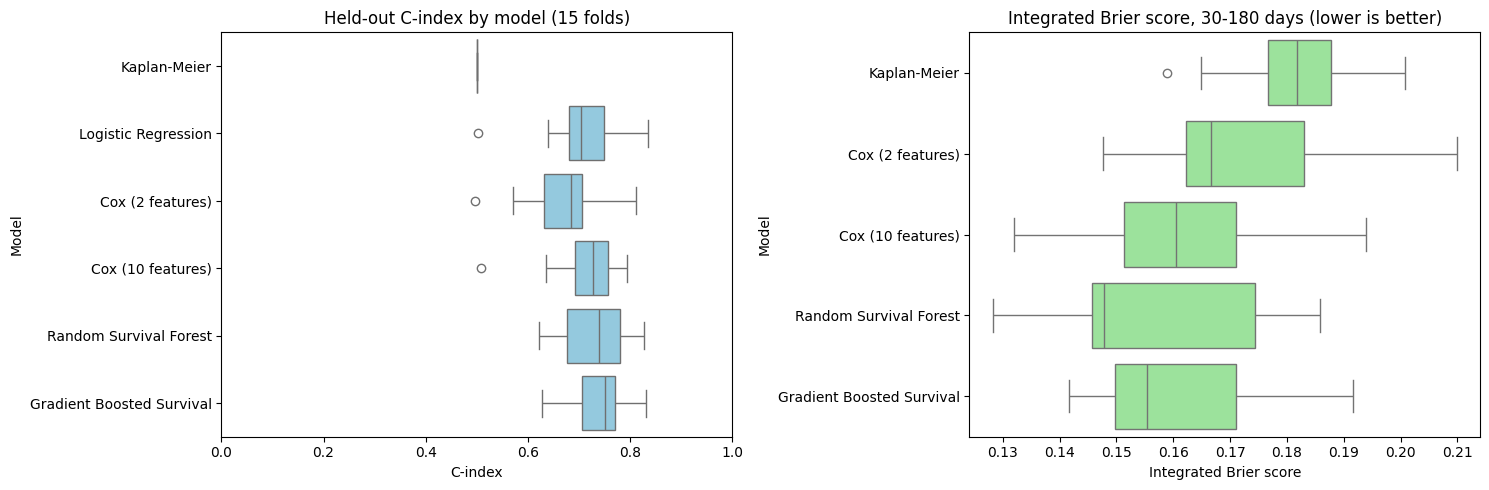

In [ ]:
model_summary = (
    fold_metrics.groupby("Model", as_index = False)
    .agg(
        C_index_mean = ("C-index", "mean"),
        C_index_sd = ("C-index", "std"),
        AUC_60d = ("AUC 60d", "mean"),
        AUC_120d = ("AUC 120d", "mean"),
        AUC_180d = ("AUC 180d", "mean"),
        mean_time_AUC = ("Mean time-dependent AUC", "mean"),
        IBS_mean = ("Integrated Brier score", "mean"),
        IBS_sd = ("Integrated Brier score", "std"),
        IPCW_excluded_total = ("IPCW excluded", "sum"),
    )
    .sort_values("C_index_mean", ascending = False)
)
model_summary.to_csv(RESULTS_DIR / "model_comparison_summary.csv", index = False)
display(model_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize = (15, 5))
sns.boxplot(data = fold_metrics, y = "Model", x = "C-index", ax = axes[0], color = "skyblue")
axes[0].set_title("Held-out C-index by model (15 folds)")
axes[0].set_xlim(0, 1)
sns.boxplot(
    data = fold_metrics.dropna(subset = ["Integrated Brier score"]),
    y = "Model", x = "Integrated Brier score", ax = axes[1], color = "lightgreen"
)
axes[1].set_title("Integrated Brier score, 30-180 days (lower is better)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "cross_validation_model_comparison.png", dpi = 180, bbox_inches = "tight")
plt.show()

### Paired comparison on the same folds

Because every model is scored on exactly the same 15 test folds, the models can be compared fold by fold. A positive mean difference means the first model scored higher. The repeats overlap, so this is descriptive and does not give a significance test.

In [ ]:
wide_c = fold_metrics.pivot(index = "Fold", columns = "Model", values = "C-index")
comparisons = [
    ("Random Survival Forest", "Cox (10 features)"),
    ("Gradient Boosted Survival", "Cox (10 features)"),
    ("Random Survival Forest", "Gradient Boosted Survival"),
    ("Cox (10 features)", "Logistic Regression"),
    ("Cox (10 features)", "Cox (2 features)"),
]
paired_rows = []
for first, second in comparisons:
    diff = wide_c[first] - wide_c[second]
    paired_rows.append({
        "Comparison (first minus second)": f"{first} - {second}",
        "Mean C-index difference": diff.mean(),
        "SD of difference": diff.std(),
        "Folds where first is higher (of 15)": int((diff > 0).sum()),
    })
paired_table = pd.DataFrame(paired_rows)
paired_table.to_csv(RESULTS_DIR / "paired_c_index_differences.csv", index = False)
display(paired_table.round(3))

,Comparison (first minus second),Mean C-index difference,SD of difference,Folds where first is higher (of 15)
0,Random Survival Forest - Cox (10 features),0.025,0.041,11
1,Gradient Boosted Survival - Cox (10 features),0.021,0.039,9
2,Random Survival Forest - Gradient Boosted Surv...,0.004,0.029,8
3,Cox (10 features) - Logistic Regression,0.001,0.019,8
4,Cox (10 features) - Cox (2 features),0.037,0.052,12


Read the table together with the standard deviations above: a mean difference of about 0.02 with a fold-to-fold spread of 0.03 to 0.06 is not strong evidence that one model is better. If a model is higher in almost every fold (for example 14 or 15 of 15), that is more convincing than the mean alone.

### ML feature importance

The following is permutation importance **on the held-out outer folds** for the
two ML survival models. Positive importance means that shuffling that feature
reduced the model's C-index. Negative values can occur due to sampling variation
and correlated predictors; they should not be treated as causal effects.

,Model,Feature,mean_importance,sd_importance
4,Gradient Boosted Survival,ejection_fraction,0.0900,0.0403
7,Gradient Boosted Survival,serum_creatinine,0.0767,0.0235
0,Gradient Boosted Survival,age,0.0602,0.0347
2,Gradient Boosted Survival,creatinine_phosphokinase,0.0021,0.0076
5,Gradient Boosted Survival,high_blood_pressure,0.0004,0.0043
9,Gradient Boosted Survival,sex,0.0000,0.0001
3,Gradient Boosted Survival,diabetes,-0.0000,0.0001
6,Gradient Boosted Survival,platelets,-0.0003,0.0011
1,Gradient Boosted Survival,anaemia,-0.0009,0.0040
8,Gradient Boosted Survival,serum_sodium,-0.0021,0.0041


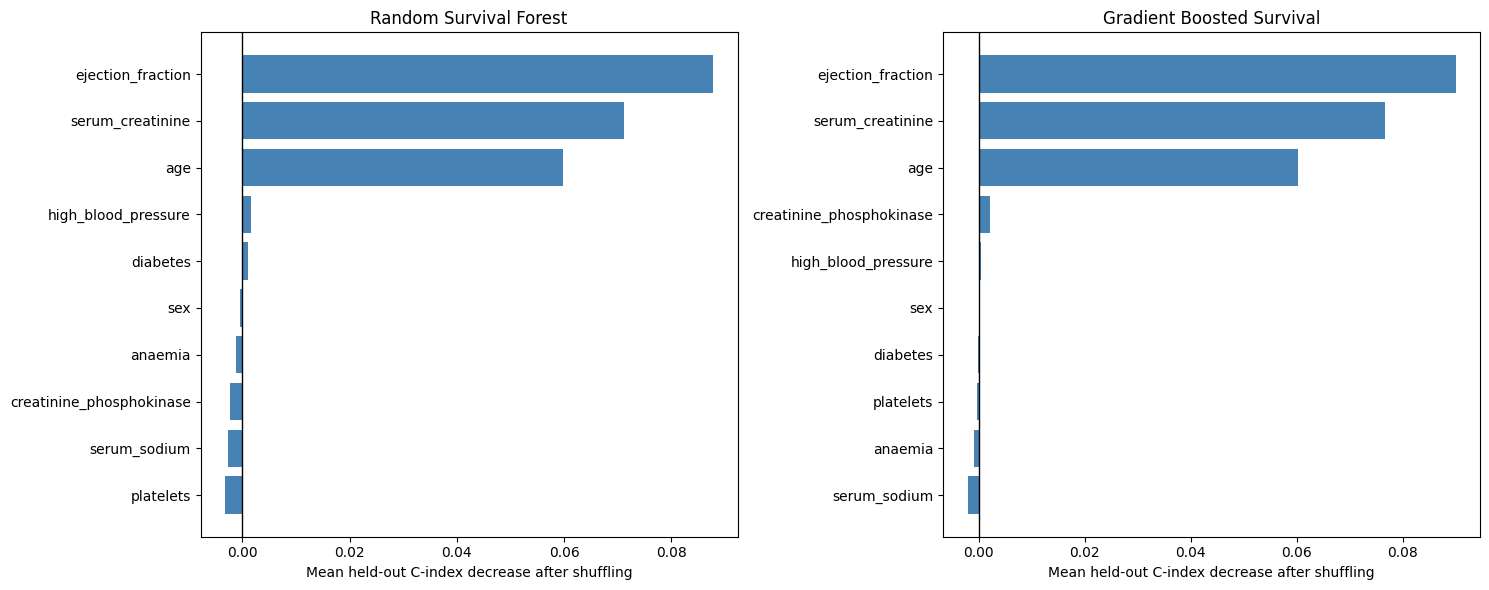

In [ ]:
mean_importance = (
    importance_table.groupby(["Model", "Feature"], as_index = False)
    .agg(mean_importance = ("Importance", "mean"),
         sd_importance = ("Importance", "std"))
)
mean_importance.to_csv(RESULTS_DIR / "heldout_feature_importance.csv", index = False)
display(mean_importance.sort_values(
    ["Model", "mean_importance"], ascending = [True, False]
).round(4))

fig, axes = plt.subplots(1, 2, figsize = (15, 6))
for ax, name in zip(axes, ["Random Survival Forest", "Gradient Boosted Survival"]):
    subset = mean_importance[mean_importance["Model"] == name].sort_values("mean_importance")
    ax.barh(subset["Feature"], subset["mean_importance"], color = "steelblue")
    ax.axvline(0, color = "black", lw = 1)
    ax.set_title(name)
    ax.set_xlabel("Mean held-out C-index decrease after shuffling")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ml_feature_importance.png", dpi = 180, bbox_inches = "tight")
plt.show()

### Error analysis: which patient groups are harder to rank?

For a descriptive subgroup check, choose the highest mean outer-fold C-index
among the four survival regression/ML models. Subgroup C-indices are calculated within each held-out fold, then averaged over folds with enough comparable
patients. Repeats are dependent and subgroups are small, so these numbers are
exploratory, not proof of clinical bias or subgroup superiority.

Best mean CV C-index (survival models): Random Survival Forest


,Group type,Group,Unique patients,Deaths,Folds with comparable pairs,Mean subgroup C-index
0,Age group,65+,115,50,15,0.699
1,Age group,<65,184,46,15,0.725
2,EF group,40%+,117,23,15,0.775
3,EF group,<40%,182,73,15,0.702
4,Creatinine group,<=1.5,232,53,15,0.705
5,Creatinine group,>1.5,67,43,15,0.663
6,Sex group,0,105,34,15,0.757
7,Sex group,1,194,62,15,0.731


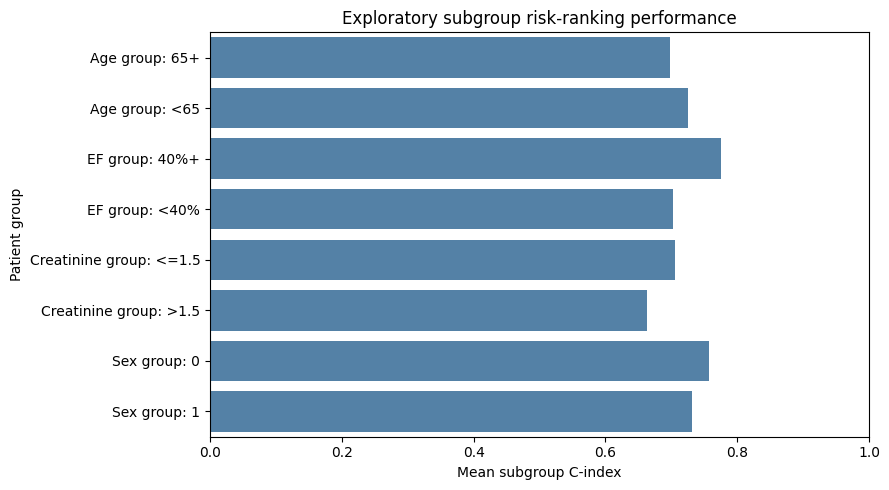

In [ ]:
survival_model_names = [
    "Cox (2 features)", "Cox (10 features)",
    "Random Survival Forest", "Gradient Boosted Survival"
]
best_survival_name = (
    model_summary[model_summary["Model"].isin(survival_model_names)]
    .iloc[0]["Model"]
)
print("Best mean CV C-index (survival models):", best_survival_name)

best_predictions = heldout_predictions[
    heldout_predictions["Model"] == best_survival_name
].copy()
details = X_survival.copy()
details["Patient"] = np.arange(len(details))
best_predictions = best_predictions.merge(details, on = "Patient", how = "left")

best_predictions["Age group"] = np.where(best_predictions["age"] < 65, "<65", "65+")
best_predictions["EF group"] = np.where(
    best_predictions["ejection_fraction"] < 40, "<40%", "40%+"
)
best_predictions["Creatinine group"] = np.where(
    best_predictions["serum_creatinine"] > 1.5, ">1.5", "<=1.5"
)
best_predictions["Sex group"] = best_predictions["sex"].map({0.0: "0", 1.0: "1"})

group_reports = []
for group_col in ["Age group", "EF group", "Creatinine group", "Sex group"]:
    for group_value, group_data in best_predictions.groupby(group_col):
        fold_c_indices = []
        for _, sample in group_data.groupby("Fold"):
            # Skip tiny or non-comparable subgroups.
            if (len(sample) < 6 or sample["Event"].sum() < 2
                    or (~sample["Event"]).sum() < 2):
                continue
            try:
                fold_c_indices.append(concordance_index_censored(
                    sample["Event"].to_numpy(dtype = bool),
                    sample["Time"].to_numpy(dtype = float),
                    sample["Risk"].to_numpy(dtype = float)
                )[0])
            except ValueError:
                pass
        distinct = group_data.drop_duplicates("Patient")
        group_reports.append({
            "Group type": group_col,
            "Group": str(group_value),
            "Unique patients": len(distinct),
            "Deaths": int(distinct["Event"].sum()),
            "Folds with comparable pairs": len(fold_c_indices),
            "Mean subgroup C-index": (
                float(np.mean(fold_c_indices)) if fold_c_indices else np.nan
            ),
        })

subgroup_results = pd.DataFrame(group_reports)
subgroup_results.to_csv(RESULTS_DIR / "subgroup_error_analysis.csv", index = False)
display(subgroup_results.round(3))

chart_data = subgroup_results.dropna(subset=["Mean subgroup C-index"]).copy()
chart_data["Patient group"] = chart_data["Group type"] + ": " + chart_data["Group"]
plt.figure(figsize = (9, 5))
sns.barplot(data = chart_data, y = "Patient group", x = "Mean subgroup C-index", color = "steelblue")
plt.xlim(0, 1)
plt.title("Exploratory subgroup risk-ranking performance")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "subgroup_error_analysis.png", dpi = 180, bbox_inches = "tight")
plt.show()

### Interpretation of Cox hazard ratios

For a fair comparison the newly fitted Cox model scales features within each
training split. The table below refits the ten-feature Cox model on all 299
records only for descriptive coefficients. Hazard ratios refer to a one standard
deviation increase in the corresponding feature, not one original unit.
They express association with the hazard under the proportional hazards assumption,
not causation. The lifelines proportional-hazards check earlier in this notebook flagged
ejection fraction, serum creatinine and serum sodium, so these hazard ratios are
average effects over follow-up.

In [ ]:
cox_descriptive = make_pipeline(
    StandardScaler(), CoxPHSurvivalAnalysis(alpha = 0.1)
).fit(X_survival, y_survival)
cox_coefficients = cox_descriptive[-1].coef_
hazard_ratios = pd.DataFrame({
    "Feature": selected_features,
    "Log hazard ratio (per SD)": cox_coefficients,
    "Hazard ratio (per SD)": np.exp(cox_coefficients),
}).sort_values("Hazard ratio (per SD)", ascending = False)
hazard_ratios.to_csv(RESULTS_DIR / "cox_standardized_hazard_ratios.csv", index = False)
display(hazard_ratios.round(3))

,Feature,Log hazard ratio (per SD),Hazard ratio (per SD)
0,age,0.543,1.722
7,serum_creatinine,0.322,1.379
5,high_blood_pressure,0.225,1.253
1,anaemia,0.220,1.246
2,creatinine_phosphokinase,0.215,1.240
3,diabetes,0.064,1.066
6,platelets,-0.043,0.958
9,sex,-0.090,0.914
8,serum_sodium,-0.195,0.823
4,ejection_fraction,-0.578,0.561


### Single-event cumulative incidence (and the competing-risks limitation)

The dataset identifies only death versus censored follow-up and does not specify
any other event type or causes of death. We therefore cannot estimate genuine
competing-risk cause-specific hazards or compare event-type cumulative incidence
functions. With one observed event type, the nonparametric cumulative incidence
of death is simply `1 - Kaplan–Meier survival`

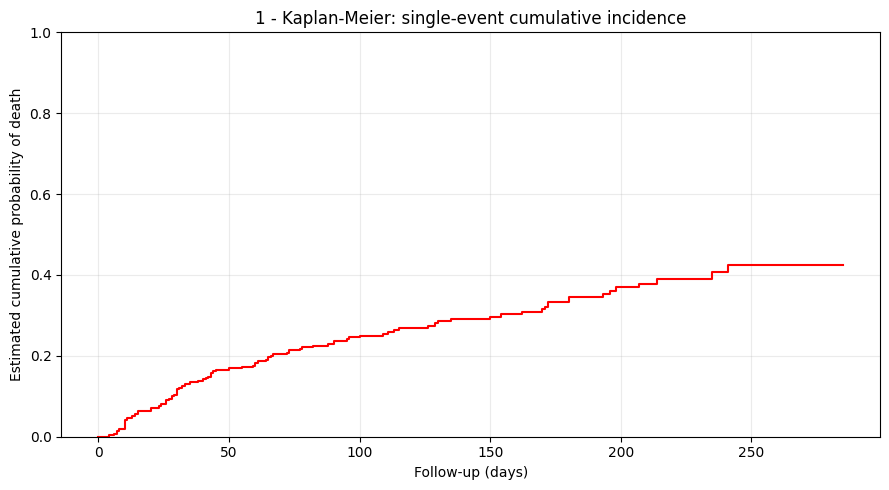

In [ ]:
km_all = KaplanMeierFitter().fit(
    y_survival["time"], event_observed=y_survival["event"],
    label="Observed all-cause death"
)
event_cdf = 1 - km_all.survival_function_.iloc[:, 0]
plt.figure(figsize = (9, 5))
plt.step(event_cdf.index, event_cdf.values, where = "post", color = "red")
plt.xlabel("Follow-up (days)")
plt.ylabel("Estimated cumulative probability of death")
plt.title("1 - Kaplan-Meier: single-event cumulative incidence")
plt.ylim(0, 1)
plt.grid(alpha = 0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "single_event_cumulative_incidence.png",
            dpi = 180, bbox_inches = "tight")
plt.show()

### Fit a final model for demonstration

This refits the selected survival model on the entire dataset. If it is RSF or
Gradient Boosting, hyperparameters are selected using 3-fold CV within this
final full-data training step. This model can be demonstrated or saved, but its
training-set performance is not reported as an independent test score.
The performance estimates are those from the held-out outer CV folds above.

In [ ]:
if best_survival_name == "Random Survival Forest":
    final_search = rsf_search(inner_folds_for(y_survival))
    final_search.fit(X_survival, y_survival)
    final_estimator = final_search.best_estimator_
    final_features = selected_features
    print("Final tuned parameters:", final_search.best_params_)
elif best_survival_name == "Gradient Boosted Survival":
    final_search = gb_search(inner_folds_for(y_survival))
    final_search.fit(X_survival, y_survival)
    final_estimator = final_search.best_estimator_
    final_features = selected_features
elif best_survival_name == "Cox (2 features)":
    final_features = ["ejection_fraction", "serum_creatinine"]
    final_estimator = make_pipeline(
        StandardScaler(), CoxPHSurvivalAnalysis(alpha = 0.1)
    ).fit(X_survival[final_features], y_survival)
else:
    final_features = selected_features
    final_estimator = make_pipeline(
        StandardScaler(), CoxPHSurvivalAnalysis(alpha = 0.1)
    ).fit(X_survival, y_survival)

joblib.dump(
    {"model": final_estimator, "features": final_features,
     "model_name": best_survival_name, "auc_horizons_days": AUC_TIMES.tolist()},
    RESULTS_DIR / "final_survival_model.joblib"
)
print("Saved final model:", RESULTS_DIR / "final_survival_model.joblib")
print("Saved result files:")
for output_file in sorted(RESULTS_DIR.iterdir()):
    print(" -", output_file.name)

Final tuned parameters: {'max_features': 'sqrt', 'min_samples_leaf': 3}
Saved final model: project_results/final_survival_model.joblib
Saved result files:
 - cox_standardized_hazard_ratios.csv
 - cross_validation_model_comparison.png
 - final_survival_model.joblib
 - heldout_feature_importance.csv
 - heldout_permutation_importance_raw.csv
 - logrank_tests.csv
 - ml_feature_importance.png
 - model_comparison_summary.csv
 - nested_cv_best_parameters.csv
 - paired_c_index_differences.csv
 - single_event_cumulative_incidence.png
 - subgroup_error_analysis.csv
 - subgroup_error_analysis.png
 - survival_fold_metrics.csv
 - univariate_feature_ranking.csv




1. **Main comparison:** quote `model_comparison_summary.csv`, not the previous
   single 80/20 split, when comparing all models. All new models use the same
   outer folds, and only the two ML models are hyperparameter-tuned in inner CV.
2. **Censoring:** `DEATH_EVENT=0` means no recorded death *before the last follow-up*,
   not guaranteed long-term survival. A binary classification label loses this
   follow-up information, so logistic regression is included only as a benchmark.
3. **Metrics:** the C-index and time-dependent AUC assess discrimination; the
   integrated Brier score additionally captures time-dependent probability error.
4. **Interpretation:** held-out permutation importance is predictive, not causal;
   Cox hazard ratios depend on its proportional-hazards assumption.
5. **Limitations:** only 299 patients and 96 deaths, possible site/population bias,
   incomplete follow-up, no external validation, and no recorded competing-event
   cause. Repeated CV folds are correlated; differences do not demonstrate a
   statistically significant or clinical improvement.
6. **Ethics:** this is an educational, retrospective modelling exercise, not a
   validated clinical decision-support tool. Do not use individual predictions
   for patient care. Credit the UCI dataset and comply with its CC BY 4.0 licence.
7. **Logistic regression versus survival models:** the logistic regression has
   almost the same C-index as the ten-feature Cox model, so on discrimination
   alone binary classification is not much worse on this dataset. The advantages
   of survival models are that they handle censoring correctly and give
   time-specific survival probabilities (the integrated Brier score), which a
   binary classifier cannot produce.
8. **Paired differences:** compare models fold by fold (see the paired table)
   instead of only comparing means, and treat differences that are small compared
   with the fold-to-fold standard deviation as inconclusive.

### Results summary (seed 42)

These are the mean scores over the 15 held-out outer folds, rounded to three decimals:

| Model | Mean C-index | Mean time-dependent AUC | Mean IBS |
|---|---:|---:|---:|
| Random Survival Forest | 0.734 | 0.753 | 0.157 |
| Gradient Boosted Survival | 0.731 | 0.747 | 0.159 |
| Cox (10 features) | 0.710 | 0.725 | 0.161 |
| Logistic Regression | 0.708 | 0.722 | n/a |
| Cox (2 features) | 0.673 | 0.666 | 0.172 |
| Kaplan–Meier | 0.500 | 0.500 | 0.182 |

The results suggest similar performance from the two ML survival models,
with a small numerical edge for Random Survival Forest. The
corresponding fold-level results, hyperparameters, feature importance, subgroup
checks and graphs are included in the `project_results/` output folder.